In [1]:
import pandas as pd
import scanpy as sc

import bonsai_loop as bl

sc.set_figure_params(figsize=(5, 5))

/home/stan/Git/bonsai-loop/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad("../data/48h-1/adata_48h_hvg_raw.h5ad")
meta = pd.read_csv("../data/48h-1/adata_timeseries_old_48h-1_meta.csv", index_col=0)
adata.obs = meta.loc[adata.obs.index]
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_neighbors=15, method="gauss")
sc.tl.diffmap(adata)
del meta

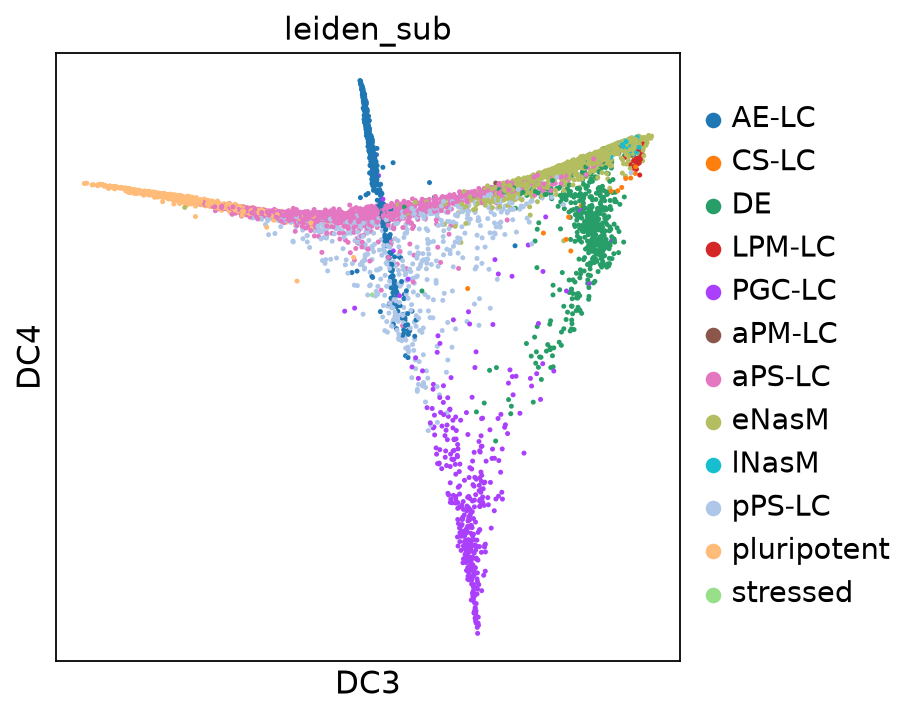

In [3]:
sc.pl.diffmap(adata, components=["3,4"], color="leiden_sub")

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from pybonsai import BonsaiOutput

BONSAI_DIR = Path("../data/48h-1/adata_48h_hvg_raw_sanity_bonsai/final_bonsai_tree")
ROOT_CELL = "AAGGAATAGAGCAGTC-1_48h"

out = BonsaiOutput(BONSAI_DIR)
node_index = {node_id: i for i, node_id in enumerate(out.node_ids)}
tree = bl.bonsai_lib.Layout_Tree()
tree.from_newick(
    (BONSAI_DIR / "tree.nwk").read_text().strip(), node_id_to_vert_ind=node_index
)
tree.root.storeParent()
if ROOT_CELL is not None:
    root_node = tree.get_vert_ind_to_node_DF()[node_index[ROOT_CELL]].parentNode
    tree.reset_root(root_node.vert_ind)
print(
    f"{int(out.is_sample.sum())} leaves, {out.n_nodes} nodes, {out.n_features} genes; "
    f"root {tree.root.nodeId!r} with {len(tree.root.childNodes)} children"
)

5927 leaves, 11636 nodes, 480 genes; root 'internal_node_9396' with 3 children


In [11]:
node_data_lookup[ROOT_CELL]

┌────────────────────────────────────┬────────────────────────────────────────────┐
│ attribute                          │ value                                      │
├────────────────────────────────────┼────────────────────────────────────────────┤
│ tree_node                          │ TreeNode(nodeId='AAGGAATAGAGCAGTC-1_48h')  │
│ topological_level                  │ 0                                          │
│ geometric_level                    │ None                                       │
│ identity                           │ [(pluripotent,1.0)]                        │
│ n_leaves                           │ 1                                          │
│ ordering_value                     │ None                                       │
│ dendrogram_coords                  │ (-0.8883250189877108, -0.9496793790077623) │
│ delta_deviation_from_parent        │ None                                       │
│ delta_deviation_from_parent_smooth │ None                                 

In [12]:
LABEL_KEY = "leiden_sub"

node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=tree,
    node_level_type="topological",
    label_lookup_leaves=adata.obs[LABEL_KEY].to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=tree,
    node_data_lookup=node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

compute depth-first ordering of nodes
root node internal_node_9396
compute node level and label


11636it [00:00, 439735.48it/s]


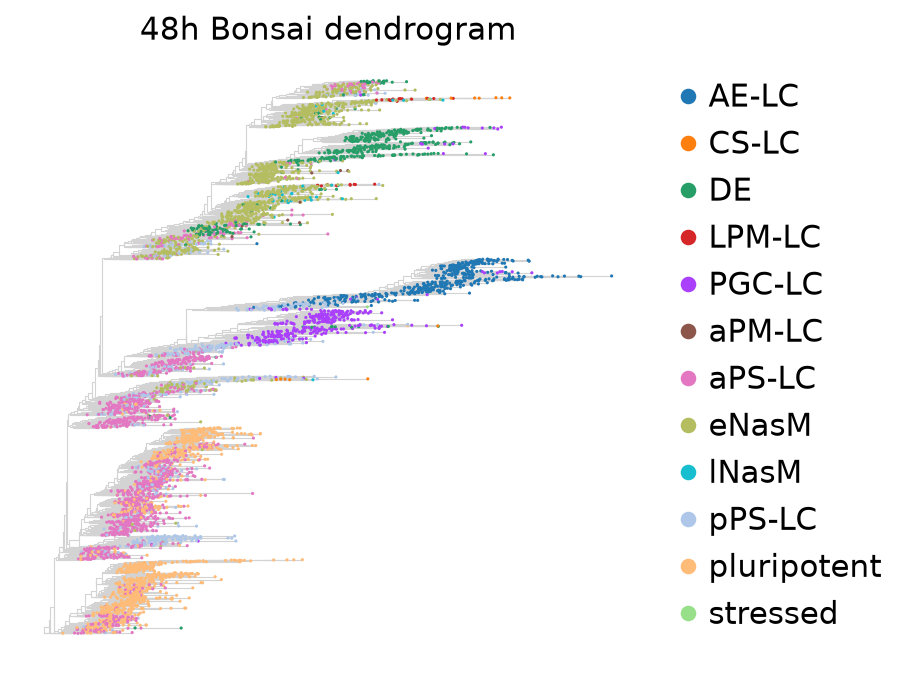

In [13]:
# ---- options -------------------------------------------------------------
FIGSIZE = (5, 5)
EDGE_COLOR = "lightgray"
EDGE_WIDTH = 0.5
LEAF_SIZE = 2  # marker area of a leaf
LEGEND_FONTSIZE = 14
SAVE_PATH = None  # e.g. "figures/48h_dendrogram.png"
# --------------------------------------------------------------------------

categories = adata.obs[LABEL_KEY].cat.categories
color_pal = dict(zip(categories, adata.uns[f"{LABEL_KEY}_colors"]))

xy = {nid: nd.dendrogram_coords for nid, nd in node_data_lookup.items()}
# one right-angle line per branch: down the parent's x, then out to the child
segs = [
    [xy[nid], (xy[nid][0], xy[child.nodeId][1]), xy[child.nodeId]]
    for nid, nd in node_data_lookup.items()
    for child in nd.tree_node.childNodes
]
leaf_ids = [nid for nid, nd in node_data_lookup.items() if nd.tree_node.isLeaf]
leaf_xy = np.array([xy[nid] for nid in leaf_ids])
leaf_colors = adata.obs.loc[leaf_ids, LABEL_KEY].map(color_pal).to_numpy()

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.add_collection(
    LineCollection(segs, colors=EDGE_COLOR, linewidths=EDGE_WIDTH, zorder=1)
)
ax.scatter(leaf_xy[:, 0], leaf_xy[:, 1], c=leaf_colors, s=LEAF_SIZE, lw=0, zorder=2)
ax.legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="", color=color_pal[c], label=c)
        for c in categories
    ],
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=LEGEND_FONTSIZE,
)
ax.set_title("48h Bonsai dendrogram")
ax.set_axis_off()
if SAVE_PATH is not None:
    fig.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [14]:
import gc

import networkx as nx
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.spatial.distance import squareform

from bonsai_loop.bonsai_lib import (
    bonsai_clustering,
    get_pdists_on_tree,
    get_pdists_on_tree_euclidean,
    get_pdists_posterior,
)

gas_bonsai_output_folder = BONSAI_DIR
gas_cell_ids = adata.obs.index.to_list()

gas_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)
gas_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=gas_bonsai_output_folder / "tree.nwk",
        cell_ids=gas_cell_ids,
    )
)
gas_euclidean_distances_tree = squareform(
    get_pdists_on_tree_euclidean(
        nwk_file=gas_bonsai_output_folder / "tree.nwk",
        bonsai_output_folder=gas_bonsai_output_folder,
        cell_ids=gas_cell_ids,
    )
)

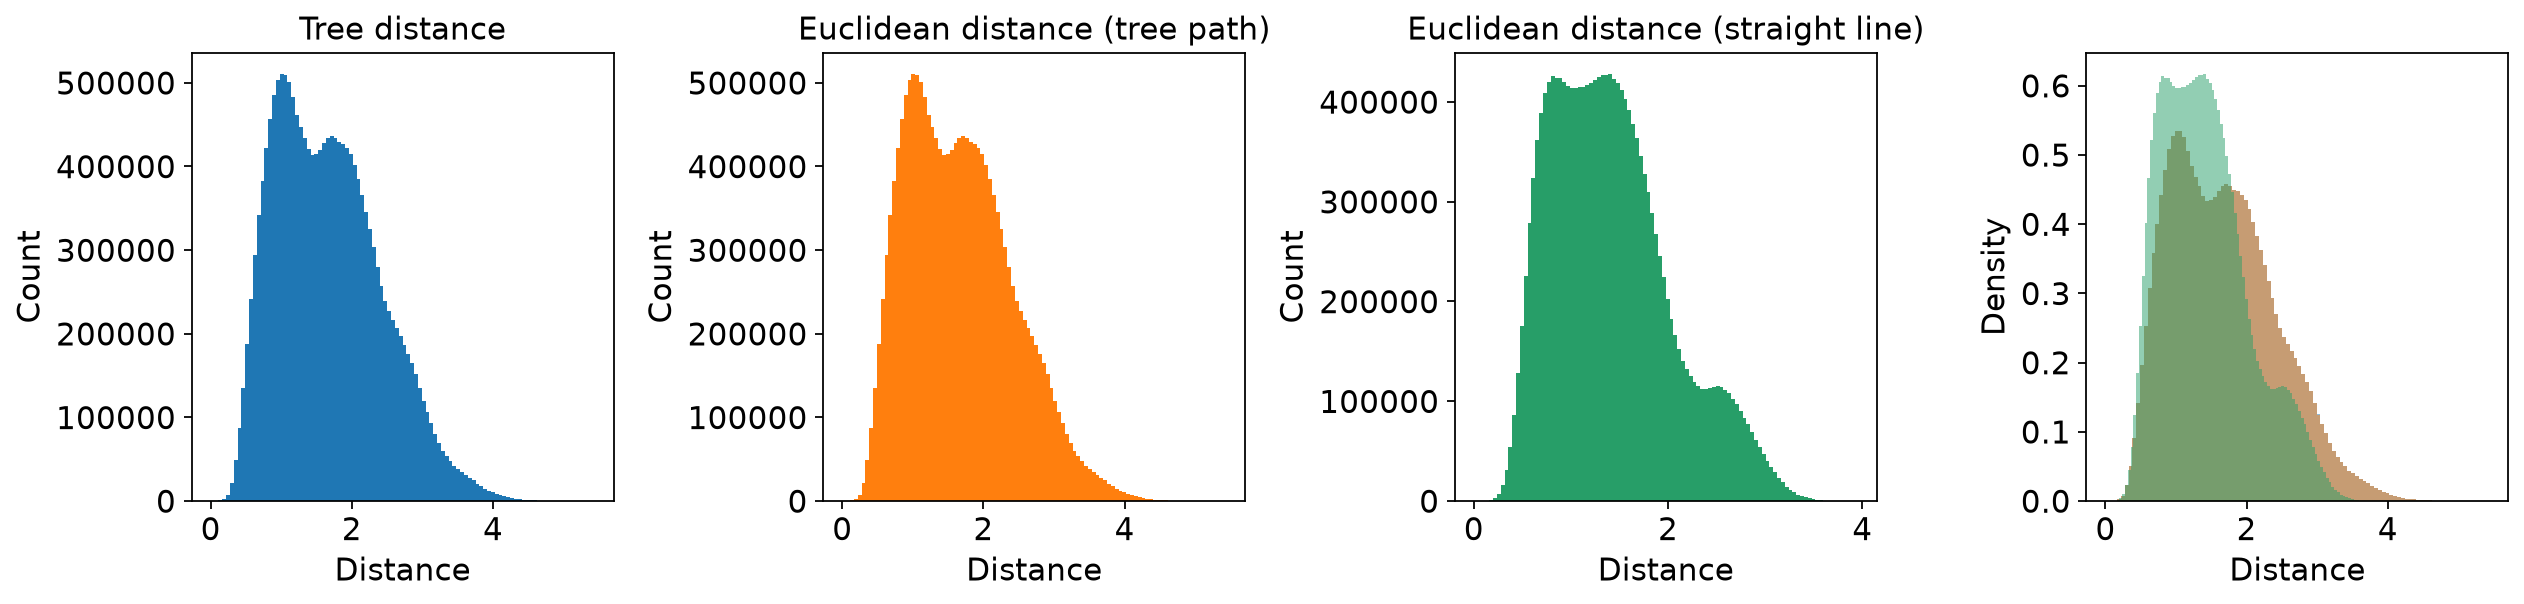

In [ ]:
# check distributions (looks matched)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].hist(squareform(gas_tree_distances), bins=100, color="C0")
axes[0].set_title("Tree distance")
axes[1].hist(
    squareform(gas_euclidean_distances_tree),
    bins=100,
    color="C1",
)
axes[1].set_title("Euclidean distance (tree path)")
axes[2].hist(
    squareform(gas_euclidean_distances_straight),
    bins=100,
    color="C2",
)
axes[2].set_title("Euclidean distance (straight line)")
for i, dists in enumerate(
    [gas_tree_distances, gas_euclidean_distances_tree, gas_euclidean_distances_straight]
):
    axes[3].hist(
        squareform(dists),
        bins=100,
        color=f"C{i}",
        alpha=0.5,
        density=True,
    )

for i, ax in enumerate(axes):
    ax.set_xlabel("Distance")
    ax.set_ylabel("Count") if i < 3 else ax.set_ylabel("Density")
    ax.grid(False)

plt.tight_layout()
plt.show()
plt.close()

In [21]:
annotation_dict = adata.obs["leiden_sub"].to_dict()
with open(gas_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()
# try not to be biased by leiden annotation
all_clusters, _ = bonsai_clustering.get_min_pdists_clustering_from_nwk_str(
    tree_nwk_str=nwk_str, n_clusters=10
)
gas_clusters = all_clusters[f"annot_bnsi_cluster_n{10}"]
cluster_dict = bonsai_clustering.get_cluster_assignments({"annot": gas_clusters})
adata.obs["bonsai_cluster"] = (
    cluster_dict["annot"].reindex(adata.obs.index).fillna("-1")
)
adata.obs["bonsai_cluster"] = adata.obs["bonsai_cluster"].astype(str).astype("category")

if "bonsai_cluster_colors" in adata.uns:
    del adata.uns["bonsai_cluster_colors"]

11-11 06:07:22 mp_print INFO 
Init min-dist clustering-tree
11-11 06:07:22 mp_print INFO Clustering has created 2 subtrees, 8 branches still to cut.
11-11 06:07:22 mp_print INFO Clustering has created 4 subtrees, 6 branches still to cut.
11-11 06:07:22 mp_print INFO Clustering has created 8 subtrees, 2 branches still to cut.


Clustering done


In [22]:
gas_cell_ids = adata.obs.index.to_list()
gas_node_id_to_vert_ind = {}
with open(gas_bonsai_output_folder / "vertex_list.tsv") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        gas_node_id_to_vert_ind[parts[1]] = int(parts[0])
cell_vert_inds = [gas_node_id_to_vert_ind[cid] for cid in gas_cell_ids]
cluster_vec = adata.obs.loc[gas_cell_ids, "bonsai_cluster"].copy()
gas_clusters = cluster_vec.cat.categories
gas_root_id = tree.root.nodeId

gas_G = nx.Graph()
with open(gas_bonsai_output_folder / "edge_list.tsv") as f:
    next(f)
    for line in f:
        v1, v2, d = line.strip().split("\t")
        gas_G.add_edge(int(v1), int(v2), weight=float(d))
gas__tree_t = nx.shortest_path_length(
    gas_G, source=gas_node_id_to_vert_ind[gas_root_id], weight="weight"
)
gas_dists_to_root = np.array([gas__tree_t[cvid] for cvid in cell_vert_inds])
gas_dists_to_root_by_cluster = np.zeros(len(gas_cell_ids))
for c in gas_clusters:
    gas_dists_to_root_by_cluster[cluster_vec == c] = np.mean(
        gas_dists_to_root[cluster_vec == c]
    )
gas_reorder_ind = np.lexsort((gas_dists_to_root, gas_dists_to_root_by_cluster))

In [23]:
gas_dist_matrix_tree_t_ordered = gas_tree_distances[gas_reorder_ind, :][
    :, gas_reorder_ind
]
gas_dist_matrix_tree_e_ordered = gas_euclidean_distances_tree[gas_reorder_ind, :][
    :, gas_reorder_ind
]
gas_dist_matrix_straight_ordered = gas_euclidean_distances_straight[gas_reorder_ind, :][
    :, gas_reorder_ind
]

In [24]:
gas_window_size = 20
gas_cell_types = pd.Categorical(adata.obs["leiden_sub"]).categories
gas_colors = adata.uns["leiden_sub_colors"]
gas_cell_composition_matrix = np.zeros((len(gas_cell_types) + 1, len(gas_cell_ids)))
for i, cell_type in enumerate(gas_cell_types):
    res = np.convolve(
        adata.obs.loc[gas_cell_ids, "leiden_sub"].iloc[gas_reorder_ind] == cell_type,
        np.ones(gas_window_size),
        mode="valid",
    )
    margin = int(np.ceil((gas_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    gas_cell_composition_matrix[i, :] = res[: gas_cell_composition_matrix.shape[1]]
gas_cell_composition_matrix[-1, :] = 1
gas_cell_composition_matrix = gas_cell_composition_matrix / np.sum(
    gas_cell_composition_matrix, axis=0
)

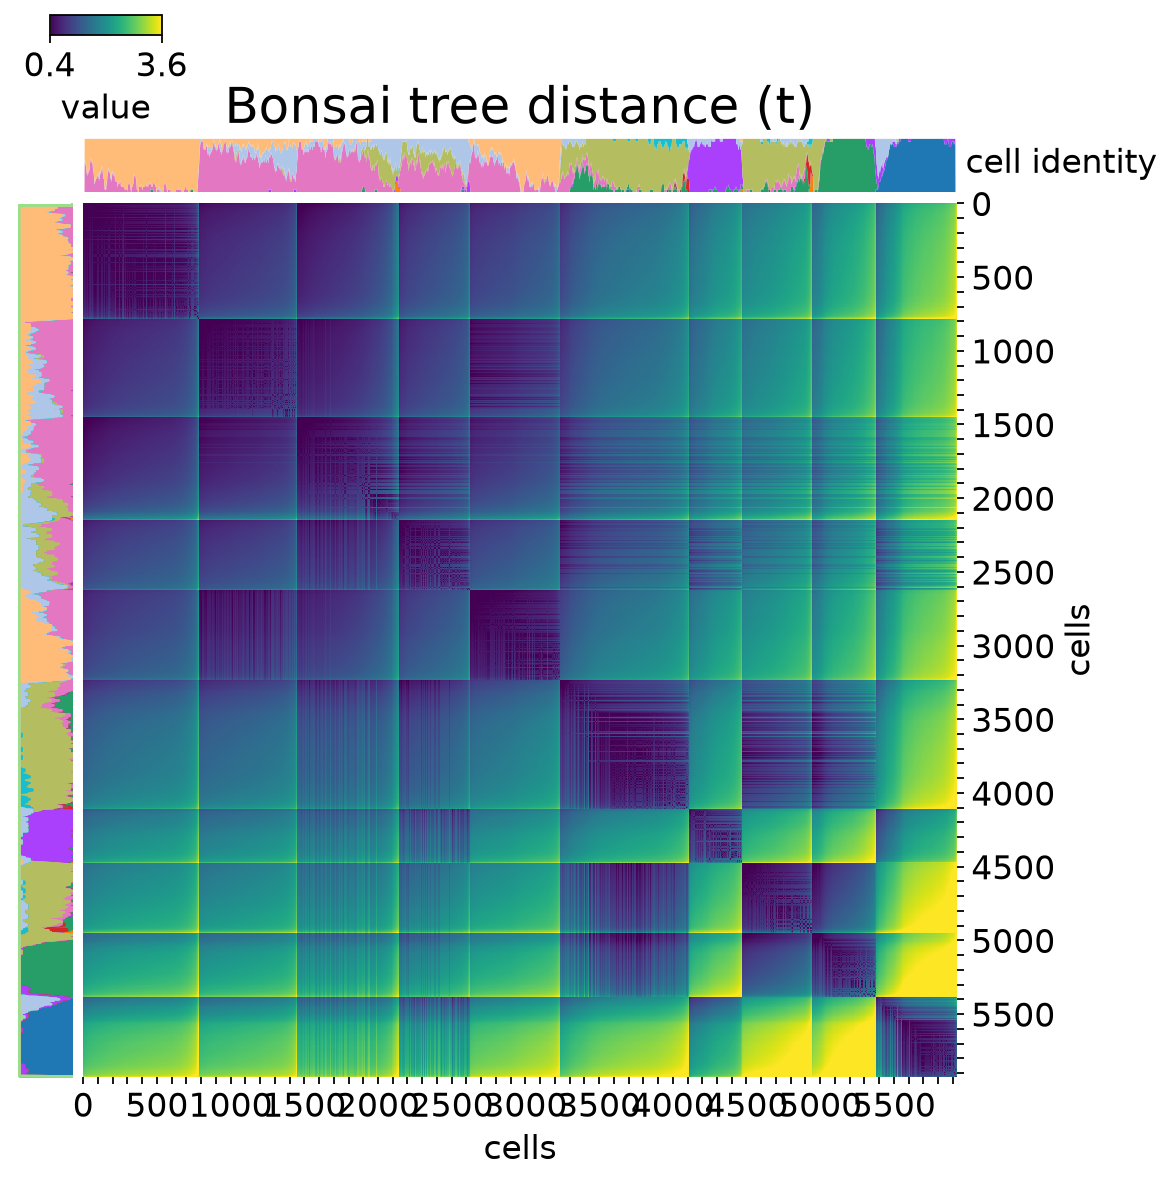

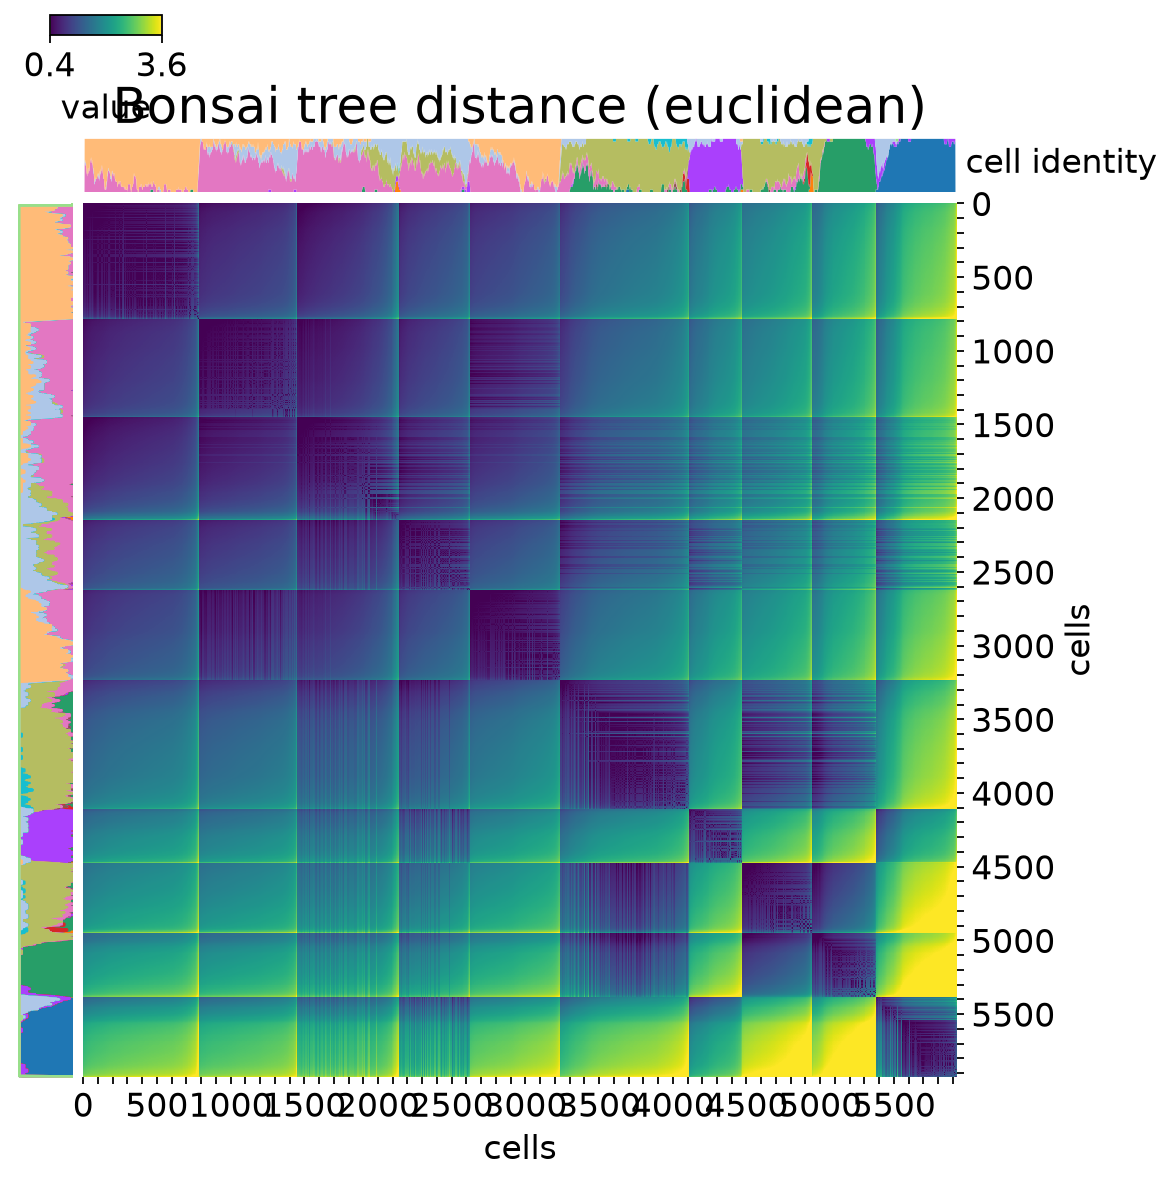

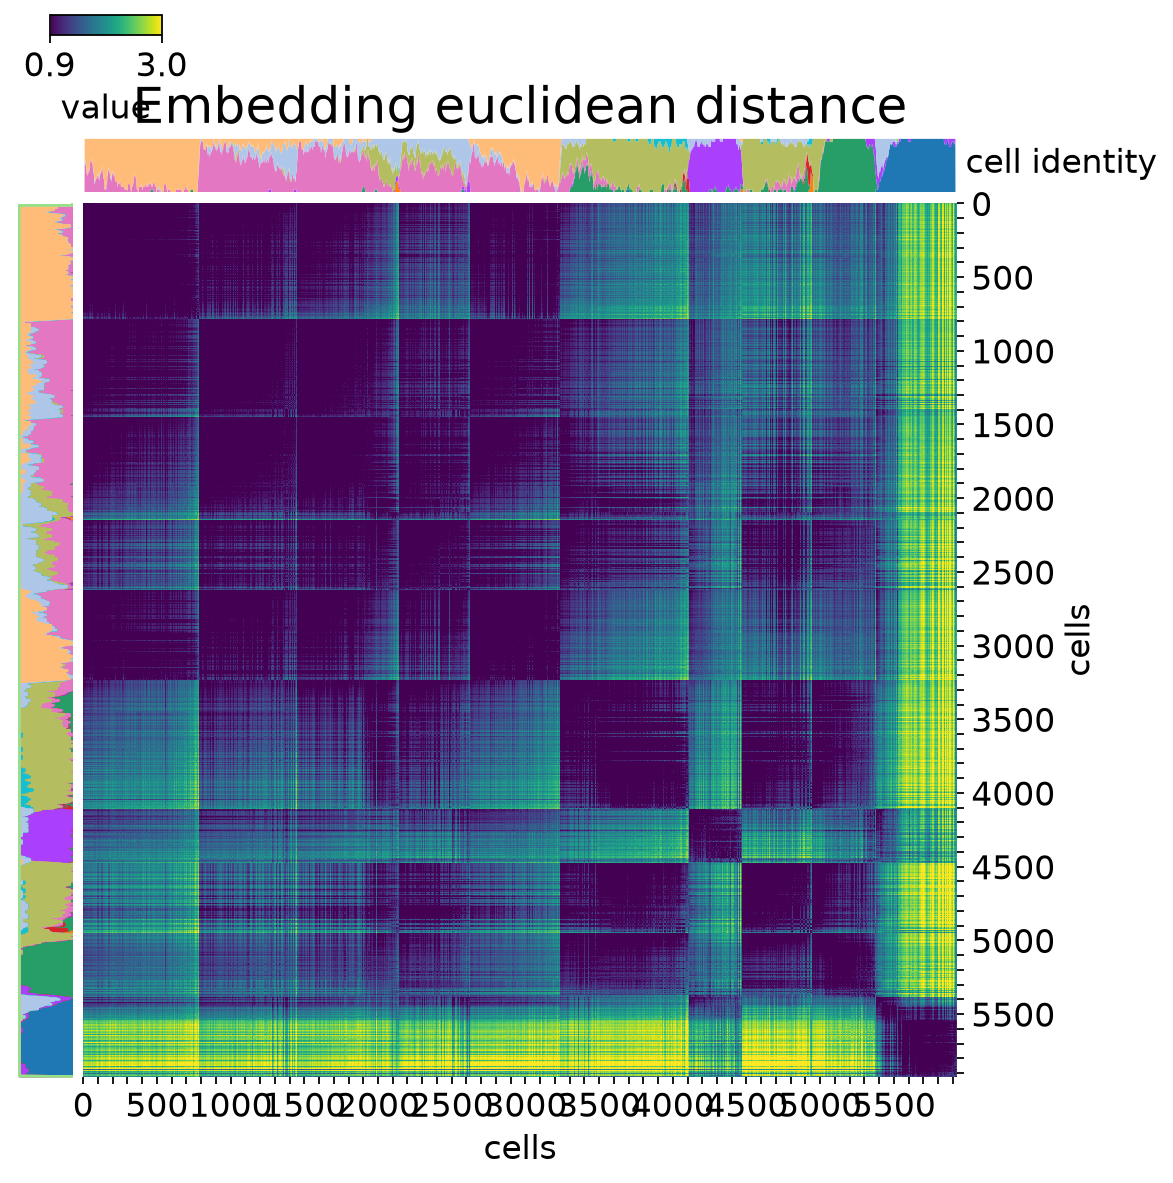

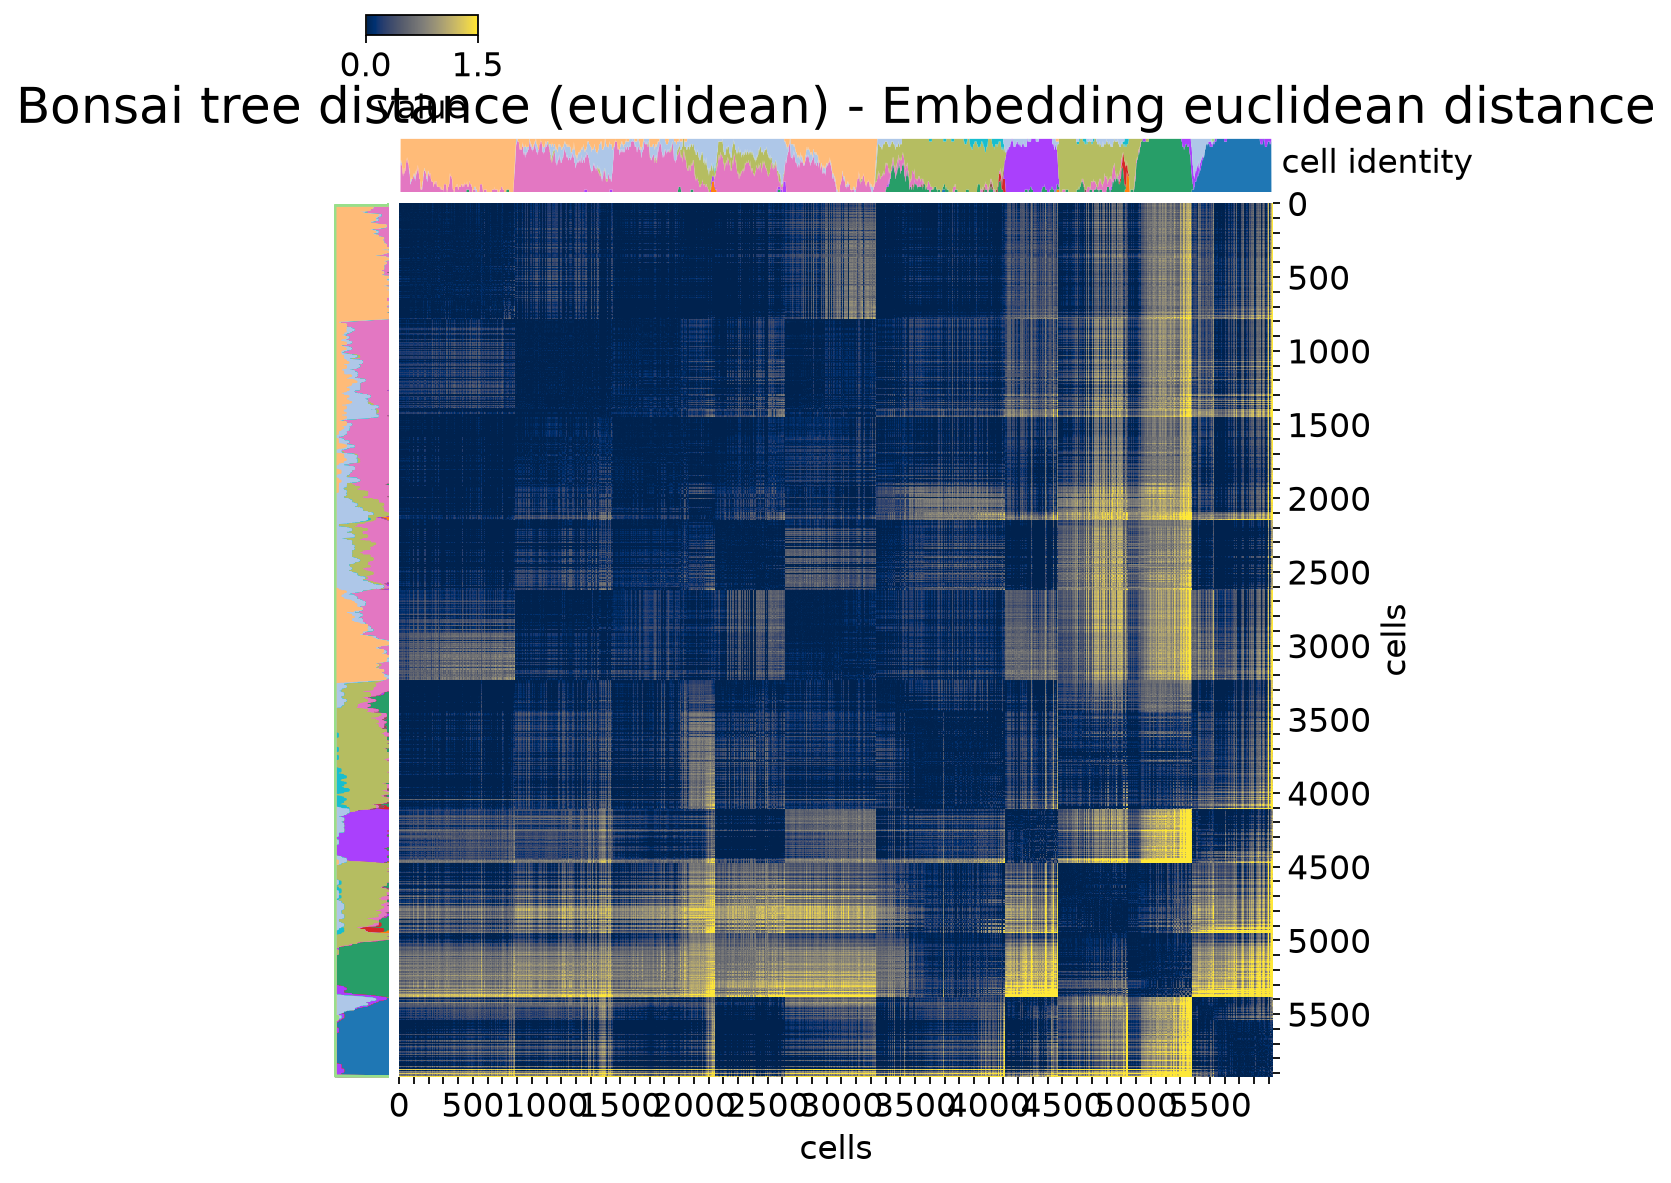

In [26]:
FONTSIZE = 15
heatmaps = [
    {
        "mat": gas_dist_matrix_tree_t_ordered,
        "title": "Bonsai tree distance (t)",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_tree_e_ordered,
        "title": "Bonsai tree distance (euclidean)",
        "cmap": "viridis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_straight_ordered,
        "title": "Embedding euclidean distance",
        "cmap": "viridis",
        "vmin_pct": 25,
        "vmax_pct": 99,
        "vmin": None,
        "vmax": None,
    },
    {
        "mat": gas_dist_matrix_tree_e_ordered - gas_dist_matrix_straight_ordered,
        "title": "Bonsai tree distance (euclidean) - Embedding euclidean distance",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0.0,
        "vmax": 1.5,
    },
]

for i, heatmap in enumerate(heatmaps):
    # make sure matrix is symmetric
    plot_mat = (heatmap["mat"] + heatmap["mat"].T) / 2

    # simple linear percentile color scaling
    vmin_pct = heatmap["vmin_pct"]
    vmax_pct = heatmap["vmax_pct"]
    if vmin_pct is None:
        vmin_pct = 0
    if vmax_pct is None:
        vmax_pct = 100
    vmin = (
        np.percentile(plot_mat, vmin_pct)
        if heatmap["vmin"] is None
        else heatmap["vmin"]
    )
    vmax = (
        np.percentile(plot_mat, vmax_pct)
        if heatmap["vmax"] is None
        else heatmap["vmax"]
    )
    norm = Normalize(vmin=vmin, vmax=vmax)

    g = sns.clustermap(
        plot_mat,
        cmap=heatmap["cmap"],
        cbar=True,
        square=False,
        xticklabels=False,
        yticklabels=False,
        row_cluster=False,
        col_cluster=False,
        figsize=(7, 7),
        rasterized=True,
        norm=norm,
    )
    ax_hm = g.ax_heatmap
    ax_hm.set_aspect("equal")
    g.ax_row_dendrogram.set_visible(False)
    g.ax_col_dendrogram.set_visible(False)
    g.cax.set_visible(False)

    ax_hm.set_position([0.1, 0.08, 0.78, 0.78])
    pos = ax_hm.get_position()

    n = plot_mat.shape[1]
    n_rows = plot_mat.shape[0]
    x = np.arange(n)
    y = np.arange(n_rows)

    tick_x = np.arange(0, n, 100)
    tick_x_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_x]
    ax_hm.set_xticks(tick_x)
    ax_hm.set_xticklabels(tick_x_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="x", which="major", length=3, direction="out")
    ax_hm.grid(False)

    tick_y = np.arange(0, n_rows, 100)
    tick_y_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_y]
    ax_hm.set_yticks(tick_y)
    ax_hm.set_yticklabels(tick_y_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="y", which="major", length=3, direction="out")
    ax_hm.set_xlabel("cells", fontsize=FONTSIZE)
    ax_hm.set_ylabel("cells", fontsize=FONTSIZE)

    ax_top = g.fig.add_axes([pos.x0, pos.y1 + 0.01, pos.width, 0.05])
    ax_top.stackplot(
        x, gas_cell_composition_matrix[:-1, :], labels=gas_cell_types, colors=gas_colors
    )
    ax_top.set_xlim(ax_hm.get_xlim())
    ax_top.axis("off")
    ax_top.text(
        1.01,
        0.5,
        "cell identity",
        transform=ax_top.transAxes,
        ha="left",
        va="center",
        rotation=0,
        fontsize=FONTSIZE,
        clip_on=False,
    )

    ax_left = g.fig.add_axes([pos.x0 - 0.06, pos.y0, 0.05, pos.height])
    cumulative = np.cumsum(gas_cell_composition_matrix[:-1, :], axis=0)
    prev = np.zeros(n_rows)
    for k in range(cumulative.shape[0]):
        ax_left.fill_betweenx(y, prev, cumulative[k], color=gas_colors[k])
        prev = cumulative[k]
    ax_left.set_xlim(1, 0)
    ax_left.set_ylim(ax_hm.get_ylim())
    ax_left.axis("off")

    ax_top.set_title(heatmap["title"], fontsize=FONTSIZE * 1.5)

    mappable = ScalarMappable(norm=norm, cmap=heatmap["cmap"])
    mappable.set_array([])
    cax = g.fig.add_axes([pos.x0 - 0.03, 1.01, 0.1, 0.018])
    cb = g.fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.set_label("value", fontsize=FONTSIZE, labelpad=4)
    if vmin < 0 < vmax:
        cb.set_ticks([vmin, 0, vmax], labels=[f"{vmin:.1f}", "0", f"{vmax:.1f}"])
    else:
        cb.set_ticks([vmin, vmax], labels=[f"{vmin:.1f}", f"{vmax:.1f}"])
    cb.ax.tick_params(labelsize=FONTSIZE)

    plt.show()
    plt.close()
    gc.collect()